In [2]:
import pandas as pd
import numpy as np
import joblib
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [3]:
df = pd.read_csv("../data/telco_clean.csv")
df.shape

(7032, 21)

In [4]:
df = df.drop("customerID", axis=1)
df.shape

(7032, 20)

In [5]:
df["Churn"] = df["Churn"].map({"No": 0, "Yes": 1})
df["Churn"].value_counts()

Churn
0    5163
1    1869
Name: count, dtype: int64

In [6]:
df = pd.get_dummies(df, drop_first=True, dtype=int)
df.shape

(7032, 31)

In [7]:
df.head()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,0,0,1,0,0,1,...,0,0,0,0,0,0,1,0,1,0
1,0,34,56.95,1889.50,0,1,0,0,1,0,...,0,0,0,0,1,0,0,0,0,1
2,0,2,53.85,108.15,1,1,0,0,1,0,...,0,0,0,0,0,0,1,0,0,1
3,0,45,42.30,1840.75,0,1,0,0,0,1,...,0,0,0,0,1,0,0,0,0,0
4,0,2,70.70,151.65,1,0,0,0,1,0,...,0,0,0,0,0,0,1,0,1,0


In [8]:
X = df.drop("Churn", axis=1)
y = df["Churn"]
print(X.shape)
print(y.shape)

(7032, 30)
(7032,)


In [9]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(X_train.shape)
print(X_test.shape)

(5625, 30)
(1407, 30)


In [10]:
print(y_train.mean())
print(y_test.mean())

0.2657777777777778
0.2658137882018479


In [11]:
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]

scaler = StandardScaler()
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])

X_train[num_cols].head()

,tenure,MonthlyCharges,TotalCharges
1408,1.321816,0.981556,1.659900
6992,-0.267410,-0.971546,-0.562252
3349,1.444064,0.837066,1.756104
4486,-1.204646,0.641092,-0.908326
3535,0.669826,-0.808787,-0.101561


In [12]:
joblib.dump(scaler, "../models/scaler.pkl")
joblib.dump(list(X.columns), "../models/columns.pkl")

['../models/columns.pkl']

In [13]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score

In [14]:
print(X_train.shape, X_test.shape)

(5625, 30) (1407, 30)


In [15]:
n_stay = (y_train == 0).sum()
n_churn = (y_train == 1).sum()
ratio = n_stay / n_churn
print(n_stay, n_churn, round(ratio, 2))

4130 1495 2.76


In [16]:
lr = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42)
lr.fit(X_train, y_train)
print("Logistic Regression trained")

Logistic Regression trained


In [17]:
rf = RandomForestClassifier(
    n_estimators=200, max_depth=8,
    class_weight="balanced", random_state=42
)
rf.fit(X_train, y_train)
print("Random Forest trained")

Random Forest trained


In [18]:
xgb = XGBClassifier(
    n_estimators=200, learning_rate=0.05, max_depth=3,
    scale_pos_weight=ratio, random_state=42,
    eval_metric="logloss"
)
xgb.fit(X_train, y_train)
print("XGBoost trained")

XGBoost trained


In [19]:
models = {"Logistic Regression": lr, "Random Forest": rf, "XGBoost": xgb}

for name, model in models.items():
    train_acc = accuracy_score(y_train, model.predict(X_train))
    test_acc = accuracy_score(y_test, model.predict(X_test))
    print(f"{name}: train = {train_acc:.3f}, test = {test_acc:.3f}")

Logistic Regression: train = 0.756, test = 0.726
Random Forest: train = 0.795, test = 0.738
XGBoost: train = 0.768, test = 0.730


In [20]:
sample = X_test.iloc[[0]]
print("Actual:", y_test.iloc[0])
print("Predicted:", xgb.predict(sample)[0])
print("Churn probability:", round(xgb.predict_proba(sample)[0][1], 3))

Actual: 0
Predicted: 0
Churn probability: 0.034


In [21]:
churners = y_test[y_test == 1].index[0]
sample2 = X_test.loc[[churners]]
print("Actual:", y_test.loc[churners])
print("Predicted:", xgb.predict(sample2)[0])
print("Churn probability:", round(xgb.predict_proba(sample2)[0][1], 3))

Actual: 1
Predicted: 0
Churn probability: 0.288


In [22]:
joblib.dump(lr, "../models/logistic_model.pkl")
joblib.dump(rf, "../models/rf_model.pkl")
joblib.dump(xgb, "../models/xgb_model.pkl")

['../models/xgb_model.pkl']

In [23]:
import matplotlib.pyplot as plt
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, precision_score,
                             recall_score, f1_score, roc_auc_score, roc_curve)

In [24]:
y_pred = xgb.predict(X_test)
print(classification_report(y_test, y_pred, target_names=["Stayed", "Churned"]))

              precision    recall  f1-score   support

      Stayed       0.91      0.70      0.79      1033
     Churned       0.50      0.80      0.61       374

    accuracy                           0.73      1407
   macro avg       0.70      0.75      0.70      1407
weighted avg       0.80      0.73      0.74      1407



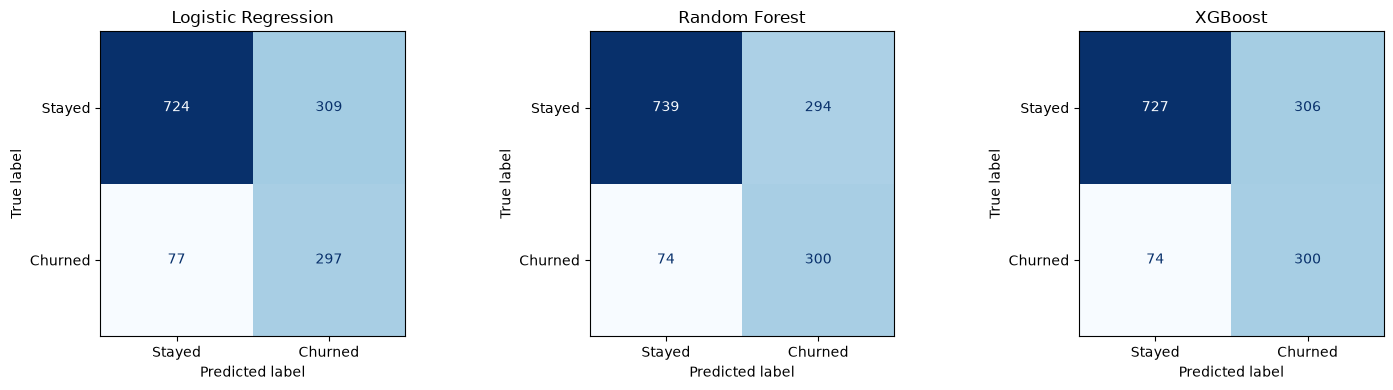

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, model) in zip(axes, models.items()):
    ConfusionMatrixDisplay.from_estimator(
        model, X_test, y_test, ax=ax, cmap="Blues",
        display_labels=["Stayed", "Churned"], colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

In [26]:
rows = []
for name, model in models.items():
    pred = model.predict(X_test)
    proba = model.predict_proba(X_test)[:, 1]
    rows.append({
        "Model": name,
        "Accuracy": round(accuracy_score(y_test, pred), 3),
        "Precision": round(precision_score(y_test, pred), 3),
        "Recall": round(recall_score(y_test, pred), 3),
        "F1": round(f1_score(y_test, pred), 3),
        "ROC-AUC": round(roc_auc_score(y_test, proba), 3),
    })

results = pd.DataFrame(rows)
results

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.726,0.490,0.794,0.606,0.835
1,Random Forest,0.738,0.505,0.802,0.620,0.838
2,XGBoost,0.730,0.495,0.802,0.612,0.839


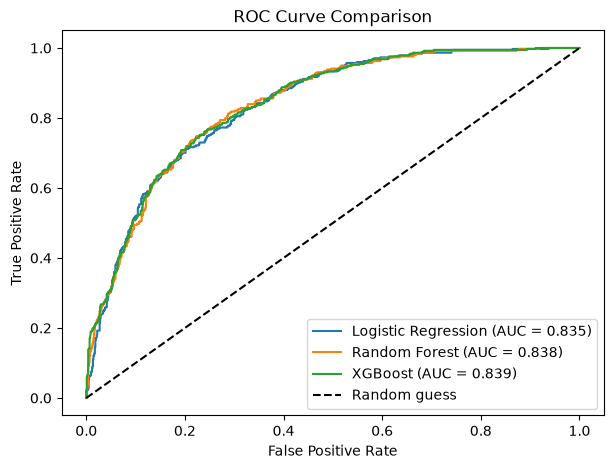

In [27]:
plt.figure(figsize=(7, 5))
for name, model in models.items():
    proba = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, proba)
    auc = roc_auc_score(y_test, proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")

plt.plot([0, 1], [0, 1], "k--", label="Random guess")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.show()


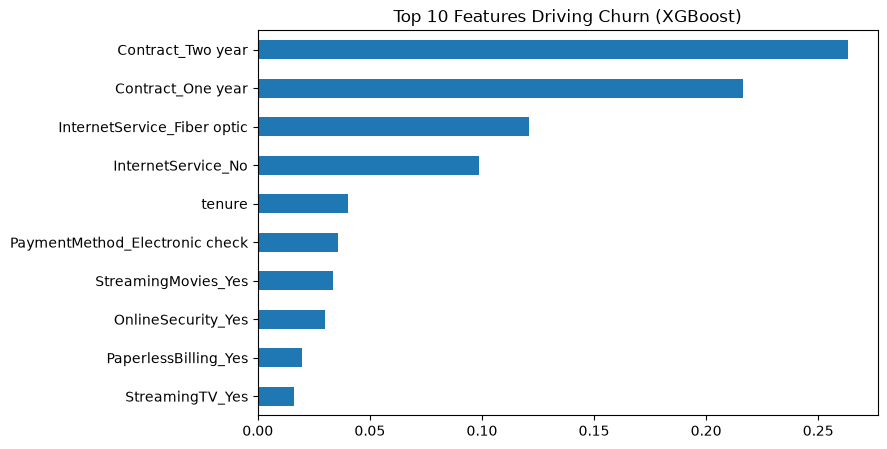

In [28]:
importance = pd.Series(xgb.feature_importances_, index=X_train.columns)
importance.sort_values().tail(10).plot(kind="barh", figsize=(8, 5))
plt.title("Top 10 Features Driving Churn (XGBoost)")
plt.show()

In [29]:
proba = xgb.predict_proba(X_test)[:, 1]

for t in [0.4, 0.5, 0.6, 0.7,0.8,0.9]:
    pred = (proba >= t).astype(int)
    print(f"cut-off {t}: accuracy={accuracy_score(y_test, pred):.3f}, "
          f"precision={precision_score(y_test, pred):.3f}, "
          f"recall={recall_score(y_test, pred):.3f}, "
          f"f1={f1_score(y_test, pred):.3f}")

cut-off 0.4: accuracy=0.694, precision=0.460, recall=0.853, f1=0.597
cut-off 0.5: accuracy=0.730, precision=0.495, recall=0.802, f1=0.612
cut-off 0.6: accuracy=0.768, precision=0.547, recall=0.730, f1=0.625
cut-off 0.7: accuracy=0.797, precision=0.626, recall=0.583, f1=0.604
cut-off 0.8: accuracy=0.785, precision=0.690, recall=0.345, f1=0.460
cut-off 0.9: accuracy=0.768, precision=0.929, recall=0.139, f1=0.242


In [30]:
best_model = xgb
best_threshold = 0.7

joblib.dump(best_model, "../models/best_model.pkl")
joblib.dump(best_threshold, "../models/threshold.pkl")
results.to_csv("../models/model_comparison.csv", index=False)
print("Saved")

Saved


In [31]:
from sklearn.model_selection import StratifiedKFold, cross_val_score, RandomizedSearchCV

In [32]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for name, model in models.items():
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="roc_auc")
    print(f"{name}: mean AUC = {scores.mean():.3f}, std = {scores.std():.3f}")

Logistic Regression: mean AUC = 0.846, std = 0.005
Random Forest: mean AUC = 0.848, std = 0.006
XGBoost: mean AUC = 0.848, std = 0.005


In [33]:
param_grid = {
    "n_estimators": [100, 200, 300, 400],
    "max_depth": [2, 3, 4, 5],
    "learning_rate": [0.01, 0.03, 0.05, 0.1],
    "subsample": [0.7, 0.8, 1.0],
    "colsample_bytree": [0.7, 0.8, 1.0],
    "min_child_weight": [1, 3, 5],
}

search = RandomizedSearchCV(
    XGBClassifier(scale_pos_weight=ratio, random_state=42, eval_metric="logloss"),
    param_grid, n_iter=30, scoring="roc_auc", cv=cv,
    random_state=42, n_jobs=-1, verbose=1)
search.fit(X_train, y_train)

print("Best settings:", search.best_params_)
print("Best CV AUC:", round(search.best_score_, 3))

Fitting 5 folds for each of 30 candidates, totalling 150 fits
Best settings: {'subsample': 0.8, 'n_estimators': 100, 'min_child_weight': 1, 'max_depth': 5, 'learning_rate': 0.03, 'colsample_bytree': 0.8}
Best CV AUC: 0.85


In [34]:
tuned = search.best_estimator_

for name, m in [("XGBoost (original)", xgb), ("XGBoost (tuned)", tuned)]:
    proba = m.predict_proba(X_test)[:, 1]
    pred = (proba >= 0.5).astype(int)
    print(f"{name}: accuracy={accuracy_score(y_test, pred):.3f}, "
          f"recall={recall_score(y_test, pred):.3f}, "
          f"f1={f1_score(y_test, pred):.3f}, "
          f"AUC={roc_auc_score(y_test, proba):.3f}")

XGBoost (original): accuracy=0.730, recall=0.802, f1=0.612, AUC=0.839
XGBoost (tuned): accuracy=0.738, recall=0.805, f1=0.620, AUC=0.841


In [35]:
proba = tuned.predict_proba(X_test)[:, 1]
for t in [0.4, 0.5, 0.6, 0.7]:
    pred = (proba >= t).astype(int)
    print(f"cut-off {t}: accuracy={accuracy_score(y_test, pred):.3f}, "
          f"precision={precision_score(y_test, pred):.3f}, "
          f"recall={recall_score(y_test, pred):.3f}, "
          f"f1={f1_score(y_test, pred):.3f}")

cut-off 0.4: accuracy=0.686, precision=0.452, recall=0.858, f1=0.592
cut-off 0.5: accuracy=0.738, precision=0.504, recall=0.805, f1=0.620
cut-off 0.6: accuracy=0.778, precision=0.567, recall=0.703, f1=0.628
cut-off 0.7: accuracy=0.799, precision=0.637, recall=0.564, f1=0.599


In [36]:
import shap
model = joblib.load("../models/best_model.pkl")
explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_test)
print(shap_values.shape)

(1407, 30)


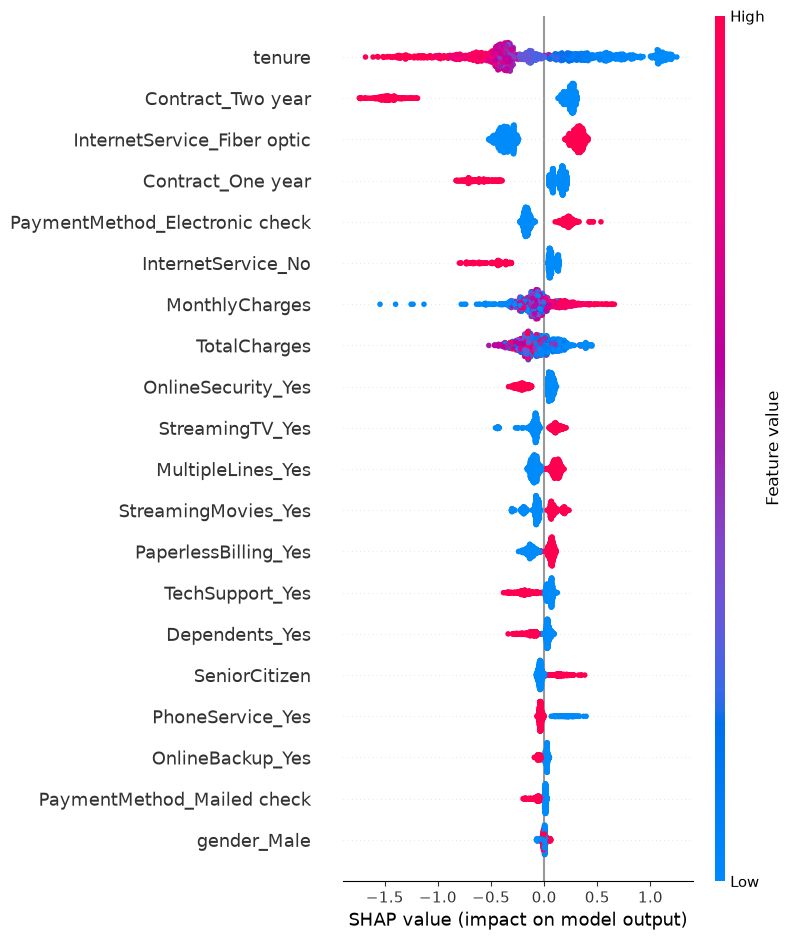

In [ ]:
shap.summary_plot(shap_values, X_test)

In [38]:
i = 0
contrib = pd.Series(shap_values[i], index=X_test.columns)
top = contrib.reindex(contrib.abs().sort_values(ascending=False).index).head(5)
print(top.round(3))

Contract_Two year             -1.525
tenure                        -0.600
InternetService_Fiber optic   -0.315
TechSupport_Yes               -0.231
Dependents_Yes                -0.224
dtype: float32
